<a href="https://colab.research.google.com/github/jyeon6273/DeepNeuralNetworks/blob/main/%5BLab_7_SSL%5D_Segmentation_Part_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning Lab ② — Semantic Segmentation
## Oxford-IIIT Pet | U-Net trained from scratch vs. frozen DINOv1 + segmentation head

**Course:** Deep Learning · **Format:** Google Colab / Jupyter · **Estimated time:** 75–95 minutes (GPU recommended)

> **Learning goals:** (1) distinguish segmentation masks from classification and detection labels, (2) implement a compact U-Net encoder-decoder with skip connections, (3) reuse pretrained DINOv1 *patch features* for dense pixel prediction, and (4) compare mask quality on the same held-out test images using IoU and Dice.

**Data choice:** [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) ships a three-class trimap: **1=pet interior, 2=background, 3=uncertain boundary**. We perform *binary* segmentation; boundary pixels are **ignored** in loss and evaluation, not silently treated as background. Both models use the *same* split and same evaluation rule.

**Before running:** Colab `Runtime → Change runtime type → T4 GPU`. The data loader reuses existing Oxford images/trimaps if sufficient pairs are available; otherwise it falls back to Hugging Face mask-labeled Oxford Pets. Internet and disk space may be required for the fallback.

### Roadmap

| Part | Activity | Approx. time |
|:---|:---|---:|
| 0 | Setup and explore pet images/trimaps | 15 min |
| 1 | Implement small U-Net; train from scratch | 25–30 min |
| 2 | Frozen DINOv1 patch features + linear head | 20–30 min |
| 3 | Evaluate, visualize and interpret masks | 20 min |

**Metric intuition:** IoU = overlapping predicted-pet pixels / union of predicted and true pet pixels. Dice = 2×overlap / (number of predicted-pet + true-pet pixels). Higher is better. We ignore trimap boundary pixels in both calculations.

## 0 · Setup

No external annotation credentials are required. PyTorch, Torchvision, NumPy and Matplotlib are normally preinstalled in Colab. We rely on the official Torchvision `OxfordIIITPet` loader and PyTorch Hub's official DINOv1 ViT-S/16 weights.

References: [Torchvision Oxford-IIIT Pet](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.OxfordIIITPet.html), [DINOv1](https://github.com/facebookresearch/dino), [Original U-Net paper](https://arxiv.org/abs/1505.04597).

In [ ]:
import math,random
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch,torch.nn as nn,torch.nn.functional as F
from torch.utils.data import Dataset,DataLoader,Subset,TensorDataset
from torchvision import transforms as T, datasets
from torchvision.transforms import InterpolationMode
from PIL import Image
from tqdm.auto import tqdm

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT=Path('/content/pet_seg_lab' if Path('/content').exists() else './pet_seg_lab')
ROOT.mkdir(parents=True,exist_ok=True)
SIZE=224
TRAIN_N,VAL_N,TEST_N=1000,200,300
BATCH=8
print('Device:',DEVICE,'| Lab folder:',ROOT)
if DEVICE.type!='cuda': print('⚠️ Use Colab GPU for feasible classroom training.')

Device: cuda | Lab folder: /content/pet_seg_lab


## 1 · Prepare and inspect Oxford-IIIT Pet segmentation masks

**Repair for incomplete downloads:** The earlier Zenodo archive preparation sometimes produced a directory that did not contain all IDs listed in the official `trainval.txt` / `test.txt`. The next cell counts valid image–mask pairs and **reuses those pairs without redownloading** when at least 1,200 train/validation and 300 test samples are available. Missing local files are excluded, never replaced with unrelated images.

If that is not possible, it uses [cvdl/oxford-pets](https://huggingface.co/datasets/cvdl/oxford-pets) with image–mask pairs already packaged in train, valid, and test partitions. This alternative labels pixels `0=pet, 1=background, 2=ambiguous`; the code converts them to Oxford's `1,2,3` encoding, so the rest of the notebook is identical.

We always use exactly **1,000 training, 200 validation, and 300 held-out test** examples. With local original files, the test set comes from Oxford's official test partition; with Hugging Face, the held-out test examples come from its supplied test partition. Masks are resized by nearest-neighbor interpolation.

In [ ]:
# Repair the Oxford-IIIT Pet dataset after an incomplete download/extraction.
# Reuse valid files already under ROOT/data/oxford-iiit-pet.
# If too few usable pairs exist, automatically load a complete mask-labeled
# alternative from Hugging Face (not the image-only Oxford Pets datasets).
import importlib.util, subprocess, sys

PET_DIR = ROOT / 'data' / 'oxford-iiit-pet'
IMAGES_DIR = PET_DIR / 'images'
MASKS_DIR = PET_DIR / 'annotations' / 'trimaps'
ANNOT_DIR = PET_DIR / 'annotations'

class LocalPetRaw(Dataset):
    """Returns PIL (image, trimap), just like Torchvision OxfordIIITPet."""
    def __init__(self, pairs):
        self.pairs = list(pairs)
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, i):
        image_path, mask_path = self.pairs[i]
        with Image.open(image_path) as im:
            img = im.convert('RGB')
        with Image.open(mask_path) as m:
            mask = m.copy()  # Preserve mask class indices (1,2,3)
        return img, mask


def read_split_rows(name):
    path = ANNOT_DIR / (name + '.txt')
    if not path.is_file():
        print('Missing split metadata:', path)
        return []
    rows = []
    for line in path.read_text().splitlines():
        parts = line.strip().split()
        if len(parts) == 4:
            rows.append(parts[0])
    return rows


def audit_local_pairs():
    print('Existing .jpg files:', len(list(IMAGES_DIR.glob('*.jpg'))))
    print('Existing trimap .png files:', len(list(MASKS_DIR.glob('*.png'))))
    print('Sample JPEG names:', [p.name for p in list(IMAGES_DIR.glob('*.jpg'))[:3]])
    print('Sample mask names:', [p.name for p in list(MASKS_DIR.glob('*.png'))[:3]])
    result = {}
    for split in ('trainval', 'test'):
        ids = read_split_rows(split)
        good, bad_image, bad_mask = [], [], []
        for id_ in ids:
            image_path = IMAGES_DIR / (id_ + '.jpg')
            mask_path = MASKS_DIR / (id_ + '.png')
            if not image_path.is_file() or image_path.stat().st_size == 0:
                bad_image.append(id_)
            if not mask_path.is_file() or mask_path.stat().st_size == 0:
                bad_mask.append(id_)
            if id_ not in bad_image and id_ not in bad_mask:
                good.append((image_path, mask_path))
        print(f'{split}: listed={len(ids)}, usable pairs={len(good)}, '
              f'missing images={len(bad_image)}, missing masks={len(bad_mask)}')
        if bad_image: print('  First missing image:', bad_image[0])
        if bad_mask: print('  First missing mask:', bad_mask[0])
        result[split] = (ids, good)
    return result

local = audit_local_pairs()
train_ids, train_pairs = local['trainval']
test_ids, test_pairs = local['test']

# IMPORTANT: no source mixing or test leakage. Only use official split IDs
# when reusing local files. Missing examples are excluded, not relabeled.
nonoverlap = bool(train_ids and test_ids and set(train_ids).isdisjoint(test_ids))
local_ready = (nonoverlap and len(train_pairs) >= TRAIN_N + VAL_N
               and len(test_pairs) >= TEST_N)
if local_ready:
    try:
        with Image.open(train_pairs[0][1]) as m:
            unique_mask_values = set(np.unique(np.asarray(m)).tolist())
        print('Local trimap values:', sorted(unique_mask_values))
        local_ready = unique_mask_values.issubset({1, 2, 3})
        if not local_ready:
            print('Unsupported local mask encoding; switching to fallback.')
    except Exception as exc:
        print('Unreadable local mask:', repr(exc))
        local_ready = False

if local_ready:
    DATA_SOURCE = 'local_oxford'
    trainval_raw = LocalPetRaw(train_pairs)
    valid_raw = trainval_raw  # Split into non-overlapping subsets next cell.
    test_raw = LocalPetRaw(test_pairs)
    print('Using existing image-mask pairs; no download needed.')
else:
    print('\nNot enough compatible Oxford image-mask pairs on disk.')
    print('Using cvdl/oxford-pets on Hugging Face, which includes segmentation masks.')
    if importlib.util.find_spec('datasets') is None:
        subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'datasets>=3.0'])
    import datasets as hf_datasets

    class HFPetRaw(Dataset):
        """Normalize Hugging Face masks to the original Oxford IDs 1,2,3."""
        def __init__(self, ds):
            self.ds = ds
        def __len__(self):
            return len(self.ds)
        def __getitem__(self, i):
            row = self.ds[int(i)]
            img = row['img'].convert('RGB')
            msk = np.asarray(row['msk'])
            if msk.ndim == 3:
                if msk.shape[2] == 1 or np.all(msk == msk[:, :, :1]):
                    msk = msk[:, :, 0]
                else:
                    raise RuntimeError('Expected a single-channel class-index mask.')
            values = set(np.unique(msk).tolist())
            if not values.issubset({0, 1, 2}):
                raise RuntimeError(f'Unexpected HF mask values: {sorted(values)}')
            # The HF source documents 0=pet, 1=background, 2=ambiguous.
            # Rest of this notebook expects 1=pet, 2=background, 3=ignored.
            msk = Image.fromarray((msk + 1).astype(np.uint8))
            return img, msk

    # Only the needed subsets are requested; HF may download whole Parquet shards.
    # We deliberately keep the provided train/valid/test partitions separate.
    hf_train = hf_datasets.load_dataset('cvdl/oxford-pets', split=f'train[:{TRAIN_N}]')
    hf_valid = hf_datasets.load_dataset('cvdl/oxford-pets', split=f'valid[:{VAL_N}]')
    hf_test = hf_datasets.load_dataset('cvdl/oxford-pets', split=f'test[:{TEST_N}]')
    trainval_raw = HFPetRaw(hf_train)
    valid_raw = HFPetRaw(hf_valid)
    test_raw = HFPetRaw(hf_test)
    DATA_SOURCE = 'huggingface_cvdl'

for name, ds in [('train pool', trainval_raw), ('val pool', valid_raw), ('test pool', test_raw)]:
    if not len(ds): raise RuntimeError(f'Empty {name} dataset!')
    img, msk = ds[0]
    mask_ids = set(np.unique(np.asarray(msk)).tolist())
    assert img.size == msk.size, f'{name}: image and mask dimensions differ'
    assert mask_ids.issubset({1, 2, 3}), (name, mask_ids)
    print(f'{name}: {len(ds)} images | example mask IDs: {sorted(mask_ids)}')
print('Dataset source:', DATA_SOURCE)


Existing .jpg files: 0
Existing trimap .png files: 0
Sample JPEG names: []
Sample mask names: []
Missing split metadata: /content/pet_seg_lab/data/oxford-iiit-pet/annotations/trainval.txt
trainval: listed=0, usable pairs=0, missing images=0, missing masks=0
Missing split metadata: /content/pet_seg_lab/data/oxford-iiit-pet/annotations/test.txt
test: listed=0, usable pairs=0, missing images=0, missing masks=0

Not enough compatible Oxford image-mask pairs on disk.
Using cvdl/oxford-pets on Hugging Face, which includes segmentation masks.


README.md:   0%|          | 0.00/2.76k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  410MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  389MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

... (4 outputs left out)

Generating train split:   0%|          | 0/2567 [00:00<?, ? examples/s]

Generating valid split:   0%|          | 0/701 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/403 [00:00<?, ? examples/s]

train pool: 1000 images | example mask IDs: [1, 2, 3]
val pool: 200 images | example mask IDs: [1, 2, 3]
test pool: 300 images | example mask IDs: [1, 2, 3]
Dataset source: huggingface_cvdl


In [ ]:
rng = np.random.default_rng(SEED)
if DATA_SOURCE == 'local_oxford':
    # The official trainval pool is split without overlap; official test is held out.
    perm = rng.permutation(len(trainval_raw))
    train_idx = perm[:TRAIN_N]
    val_idx = perm[TRAIN_N:TRAIN_N + VAL_N]
    assert not set(train_idx) & set(val_idx)
else:
    # The fallback dataset already supplies independent train/valid/test partitions.
    train_idx = np.arange(TRAIN_N)
    val_idx = np.arange(VAL_N)
test_idx = rng.permutation(len(test_raw))[:TEST_N]
print('Train / val / test:',len(train_idx),len(val_idx),len(test_idx))

image_transform=T.Compose([T.Resize((SIZE,SIZE),interpolation=InterpolationMode.BILINEAR),
                           T.ToTensor(),
                           T.Normalize([.485,.456,.406],[.229,.224,.225])])
resize_mask=T.Resize((SIZE,SIZE),interpolation=InterpolationMode.NEAREST)

class PetSegmentation(Dataset):
    def __init__(self,raw,indices):
        self.raw=raw;self.indices=list(indices)
    def __len__(self):return len(self.indices)
    def __getitem__(self,i):
        image,trimap=self.raw[self.indices[i]]
        image=image_transform(image.convert('RGB'))
        rawmask=torch.as_tensor(np.array(resize_mask(trimap)),dtype=torch.long)
        # Original Oxford IDs: 1=pet, 2=background, 3=ambiguous boundary.
        valid=(rawmask!=3).float().unsqueeze(0)
        target=(rawmask==1).float().unsqueeze(0)
        return image,target,valid

train_ds=PetSegmentation(trainval_raw,train_idx)
val_ds=PetSegmentation(valid_raw,val_idx)
test_ds=PetSegmentation(test_raw,test_idx)
train_loader=DataLoader(train_ds,batch_size=BATCH,shuffle=True,num_workers=0)
val_loader=DataLoader(val_ds,batch_size=BATCH,shuffle=False,num_workers=0)
test_loader=DataLoader(test_ds,batch_size=BATCH,shuffle=False,num_workers=0)
print('Image and target sizes:', tuple(train_ds[0][0].shape), tuple(train_ds[0][1].shape))


Train / val / test: 1000 200 300
Image and target sizes: (3, 224, 224) (1, 224, 224)


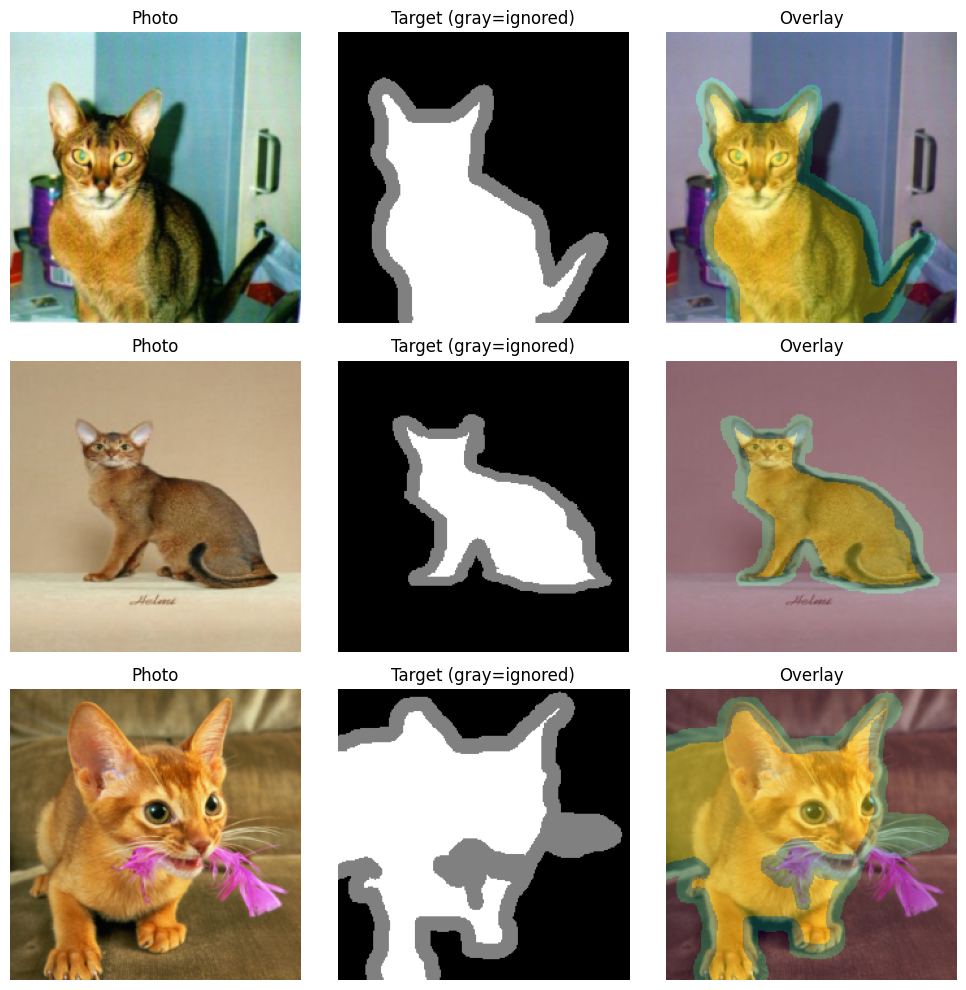

In [ ]:
def denormalize(img):
    mean=torch.tensor([.485,.456,.406])[:,None,None]
    std=torch.tensor([.229,.224,.225])[:,None,None]
    return (img.cpu()*std+mean).permute(1,2,0).clamp(0,1).numpy()

fig,axs=plt.subplots(3,3,figsize=(10,10))
for i in range(3):
    img,pet,valid=train_ds[i]
    # Gray pixels are the uncertain outline, ignored during scoring.
    plotmask=np.where(valid[0].numpy()==0,.5,pet[0].numpy())
    axs[i,0].imshow(denormalize(img)); axs[i,0].set_title('Photo')
    axs[i,1].imshow(plotmask,cmap='gray',vmin=0,vmax=1);axs[i,1].set_title('Target (gray=ignored)')
    axs[i,2].imshow(denormalize(img));axs[i,2].imshow(plotmask,alpha=.35,cmap='viridis',vmin=0,vmax=1)
    axs[i,2].set_title('Overlay')
for ax in axs.flat:ax.axis('off')
plt.tight_layout();plt.show()

### Why not classify each whole image?

Image classification predicts a single label such as *cat*. Semantic segmentation predicts a **label for each pixel**: *pet* versus *background*. Its output is a `1×224×224` logit map. We use a sigmoid to convert logits to probabilities and a threshold of 0.5 to obtain a binary mask.

**Check your understanding:** Why must mask resizing use nearest-neighbor rather than bilinear interpolation?

## 2 · U-Net from scratch

U-Net has a **contracting encoder**, a **bottleneck**, and an **expanding decoder with skip connections**. The skip connections preserve fine spatial information needed to recover fur and edges. We deliberately use a small network for classroom GPU limits.

`Image → encoder (224→112→56→28) → bottleneck → decoder (28→56→112→224) → 1-channel pixel logits`

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self,inp,out):
        super().__init__()
        self.net=nn.Sequential(nn.Conv2d(inp,out,3,padding=1,bias=False),nn.BatchNorm2d(out),nn.ReLU(True),
                               nn.Conv2d(out,out,3,padding=1,bias=False),nn.BatchNorm2d(out),nn.ReLU(True))
    def forward(self,x):return self.net(x)

class SmallUNet(nn.Module):
    def __init__(self,base=16):
        super().__init__()
        self.e1=DoubleConv(3,base)
        self.e2=DoubleConv(base,base*2)
        self.e3=DoubleConv(base*2,base*4)
        self.middle=DoubleConv(base*4,base*8)
        self.pool=nn.MaxPool2d(2)
        self.d3=DoubleConv(base*8+base*4,base*4)
        self.d2=DoubleConv(base*4+base*2,base*2)
        self.d1=DoubleConv(base*2+base,base)
        self.out=nn.Conv2d(base,1,1)
    def forward(self,x):
        a=self.e1(x);b=self.e2(self.pool(a));c=self.e3(self.pool(b))
        m=self.middle(self.pool(c))
        d=F.interpolate(m,size=c.shape[-2:],mode='bilinear',align_corners=False)
        d=self.d3(torch.cat([d,c],dim=1))
        d=F.interpolate(d,size=b.shape[-2:],mode='bilinear',align_corners=False)
        d=self.d2(torch.cat([d,b],dim=1))
        d=F.interpolate(d,size=a.shape[-2:],mode='bilinear',align_corners=False)
        d=self.d1(torch.cat([d,a],dim=1))
        return self.out(d)

unet=SmallUNet(base=16).to(DEVICE)
print('U-Net trainable parameters:',sum(p.numel() for p in unet.parameters() if p.requires_grad))
x,m,v=next(iter(train_loader))
print('Input:',x.shape,'| U-Net output:',unet(x.to(DEVICE)).shape)

U-Net trainable parameters: 488001
Input: torch.Size([8, 3, 224, 224]) | U-Net output: torch.Size([8, 1, 224, 224])


### Loss = masked BCE + soft Dice

BCE is a standard pixel-classification loss; soft Dice rewards whole-region overlap. We **multiply by `valid`** so the uncertain trimap boundary (`3`) does not contribute to either loss or evaluation.

In [ ]:
def segmentation_loss(logits,target,valid):
    bce=F.binary_cross_entropy_with_logits(logits,target,reduction='none')
    bce=(bce*valid).sum()/valid.sum().clamp_min(1)
    probs=logits.sigmoid()*valid
    target=target*valid
    intersect=(probs*target).sum(dim=(1,2,3))
    total=probs.sum(dim=(1,2,3))+target.sum(dim=(1,2,3))
    dice=1-((2*intersect+1)/(total+1)).mean()
    return bce+dice

@torch.no_grad()
def batch_scores(logits,target,valid):
    p=(logits.sigmoid()>=0.5)&valid.bool()
    y=(target>=0.5)&valid.bool()
    dims=(1,2,3)
    inter=(p&y).sum(dims).float()
    psize=p.sum(dims).float(); ysize=y.sum(dims).float()
    iou=(inter+1e-6)/(psize+ysize-inter+1e-6)
    dice=(2*inter+1e-6)/(psize+ysize+1e-6)
    return iou.cpu().tolist(),dice.cpu().tolist()

def fit_segmentation(model,train_dl,val_dl,epochs=6,lr=1e-3):
    opt=torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),lr=lr)
    history=[];best=float('inf');best_weights=None
    for ep in range(1,epochs+1):
        model.train();tl=[]
        for x,y,valid in tqdm(train_dl,desc=f'Epoch {ep}/{epochs}',leave=False):
            x,y,valid=x.to(DEVICE),y.to(DEVICE),valid.to(DEVICE)
            loss=segmentation_loss(model(x),y,valid)
            opt.zero_grad();loss.backward();opt.step();tl.append(loss.item())
        model.eval();vl=[]
        with torch.no_grad():
            for x,y,valid in val_dl:
                x,y,valid=x.to(DEVICE),y.to(DEVICE),valid.to(DEVICE)
                vl.append(segmentation_loss(model(x),y,valid).item())
        tr=float(np.mean(tl));va=float(np.mean(vl))
        history.append([ep,tr,va]);print(f'Epoch {ep:02d} | train {tr:.3f} | val {va:.3f}')
        if va<best:
            best=va;best_weights={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    model.load_state_dict(best_weights)
    return pd.DataFrame(history,columns=['epoch','train','val']).set_index('epoch')

Epoch 1/6:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 01 | train 1.033 | val 0.802


Epoch 2/6:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 02 | train 0.841 | val 0.804


Epoch 3/6:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 03 | train 0.727 | val 0.770


... (2 outputs left out)

Epoch 5/6:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 05 | train 0.655 | val 0.784


Epoch 6/6:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 06 | train 0.606 | val 0.628


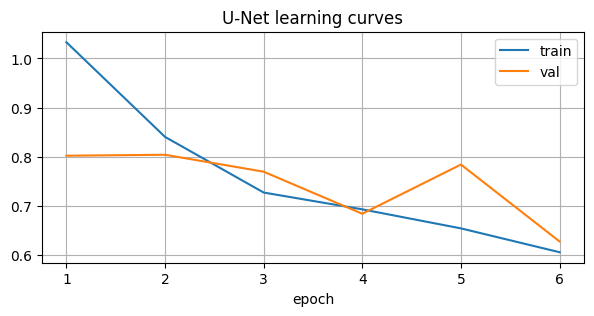

In [ ]:
UNET_EPOCHS=6
unet_history=fit_segmentation(unet,train_loader,val_loader,epochs=UNET_EPOCHS,lr=1e-3)
unet_history.plot(title='U-Net learning curves',grid=True,figsize=(7,3));plt.show()
torch.save(unet.state_dict(),ROOT/'unet_pet.pt')

## 3 · Frozen DINOv1 + trainable **segmentation head**

DINOv1 is **not a semantic segmentation model by itself**. We turn its pretrained 14×14 patch-token grid (384 channels) into a dense pixel map with a **1×1 convolutional linear classifier**, then bilinear-upsample to 224×224. This is a lightweight *linear probe* for semantic segmentation, so it is intentionally much simpler than U-Net's decoder.

`Image (224×224) → frozen DINOv1 ViT-S/16 → 384×14×14 patch features → 1×1 Conv → 1×14×14 logits → bilinear upsample → 1×224×224 mask logits`

The frozen features can be computed once and cached. This substantially reduces training time; all learnable parameters are in the head.

In [ ]:
backbone=torch.hub.load('facebookresearch/dino:main','dino_vits16',pretrained=True).to(DEVICE).eval()
for p in backbone.parameters(): p.requires_grad_(False)
print('Backbone frozen:',not any(p.requires_grad for p in backbone.parameters()))

@torch.inference_mode()
def get_dino_features(images):
    tokens=backbone.get_intermediate_layers(images.to(DEVICE),n=1)[0][:,1:,:]
    B,N,C=tokens.shape
    grid=math.isqrt(N)
    assert grid*grid==N, 'Patch tokens must form a square grid'
    return tokens.transpose(1,2).reshape(B,C,grid,grid)

@torch.no_grad()
def cache_segmentation_features(loader,name):
    out_features,out_masks,out_valid=[],[],[]
    for x,mask,valid in tqdm(loader,desc=f'Caching {name}'):
        out_features.append(get_dino_features(x).cpu().half())
        out_masks.append(mask.to(torch.uint8))
        out_valid.append(valid.to(torch.uint8))
    return TensorDataset(torch.cat(out_features),torch.cat(out_masks),torch.cat(out_valid))

# Use a non-shuffled loader for reproducible caching.
train_cache=cache_segmentation_features(DataLoader(train_ds,batch_size=16,shuffle=False,num_workers=0),'train')
val_cache=cache_segmentation_features(val_loader,'val')
test_cache=cache_segmentation_features(test_loader,'test')
print('Cached DINO feature shape:',train_cache.tensors[0].shape)

Downloading: "https://github.com/facebookresearch/dino/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dino/dino_deitsmall16_pretrain/dino_deitsmall16_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dino_deitsmall16_pretrain.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 197MB/s]


Backbone frozen: True


Caching train:   0%|          | 0/63 [00:00<?, ?it/s]

Caching val:   0%|          | 0/25 [00:00<?, ?it/s]

Caching test:   0%|          | 0/38 [00:00<?, ?it/s]

Cached DINO feature shape: torch.Size([1000, 384, 14, 14])


DINO trainable parameters: 385


Epoch 1/10:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 01 | train 0.512 | val 0.200


Epoch 2/10:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 02 | train 0.179 | val 0.157


Epoch 3/10:   0%|          | 0/63 [00:00<?, ?it/s]

... (11 outputs left out)

Epoch 9/10:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 09 | train 0.107 | val 0.110


Epoch 10/10:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 10 | train 0.105 | val 0.108


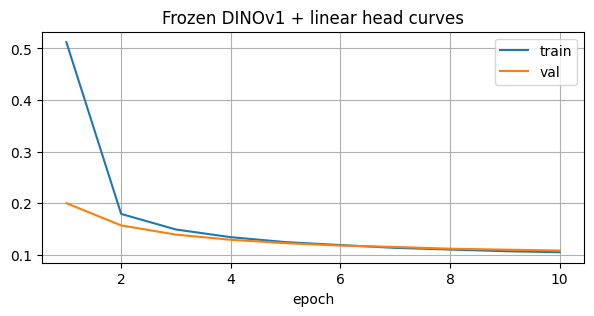

In [ ]:
class DinoLinearSegHead(nn.Module):
    def __init__(self,channels=384,output_size=224):
        super().__init__()
        self.projection=nn.Conv2d(channels,1,kernel_size=1)
        self.output_size=output_size
    def forward(self,features):
        logits=self.projection(features.float())
        return F.interpolate(logits,size=(self.output_size,self.output_size),
                             mode='bilinear',align_corners=False)

dino_head=DinoLinearSegHead().to(DEVICE)
print('DINO trainable parameters:',sum(p.numel() for p in dino_head.parameters()))

# Cached masks are byte tensors to save memory; convert back to float for the loss.
def seg_cache_collate(items):
    f,m,v=zip(*items)
    return torch.stack(f),torch.stack(m).float(),torch.stack(v).float()

train_head_loader=DataLoader(train_cache,batch_size=16,shuffle=True,collate_fn=seg_cache_collate)
val_head_loader=DataLoader(val_cache,batch_size=16,shuffle=False,collate_fn=seg_cache_collate)
test_head_loader=DataLoader(test_cache,batch_size=16,shuffle=False,collate_fn=seg_cache_collate)

HEAD_EPOCHS=10
dino_history=fit_segmentation(dino_head,train_head_loader,val_head_loader,
                              epochs=HEAD_EPOCHS,lr=1e-3)
dino_history.plot(title='Frozen DINOv1 + linear head curves',grid=True,figsize=(7,3));plt.show()
torch.save(dino_head.state_dict(),ROOT/'dino_pet_seg_head.pt')

## 4 · Compare on the **held-out test** subset

Metrics below average **per image**. Pixels labeled `3` in the original trimap are excluded identically for U-Net and DINOv1. The held-out test set has **not** been used to choose checkpoints or tune learning rates.

Test evaluation — boundary pixels ignored


,mean IoU,mean Dice
U-Net (scratch),0.6968,0.8036
DINOv1 frozen + linear head,0.9369,0.9641


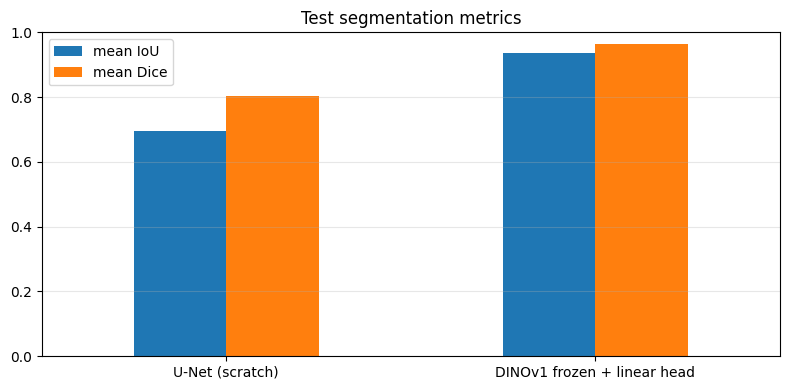

In [ ]:
@torch.no_grad()
def evaluate_seg(model,loader):
    model.eval();ious=[];dices=[]
    for x,y,valid in loader:
        logits=model(x.to(DEVICE))
        i,d=batch_scores(logits,y.to(DEVICE),valid.to(DEVICE))
        ious+=i;dices+=d
    return {'mean IoU':float(np.mean(ious)), 'mean Dice':float(np.mean(dices))}

scores=pd.DataFrame({
    'U-Net (scratch)':evaluate_seg(unet,test_loader),
    'DINOv1 frozen + linear head':evaluate_seg(dino_head,test_head_loader)
}).T
print('Test evaluation — boundary pixels ignored')
display(scores.round(4))
ax=scores.plot(kind='bar',ylim=(0,1),figsize=(8,4),rot=0,title='Test segmentation metrics')
plt.grid(axis='y',alpha=.3);plt.tight_layout();plt.show()

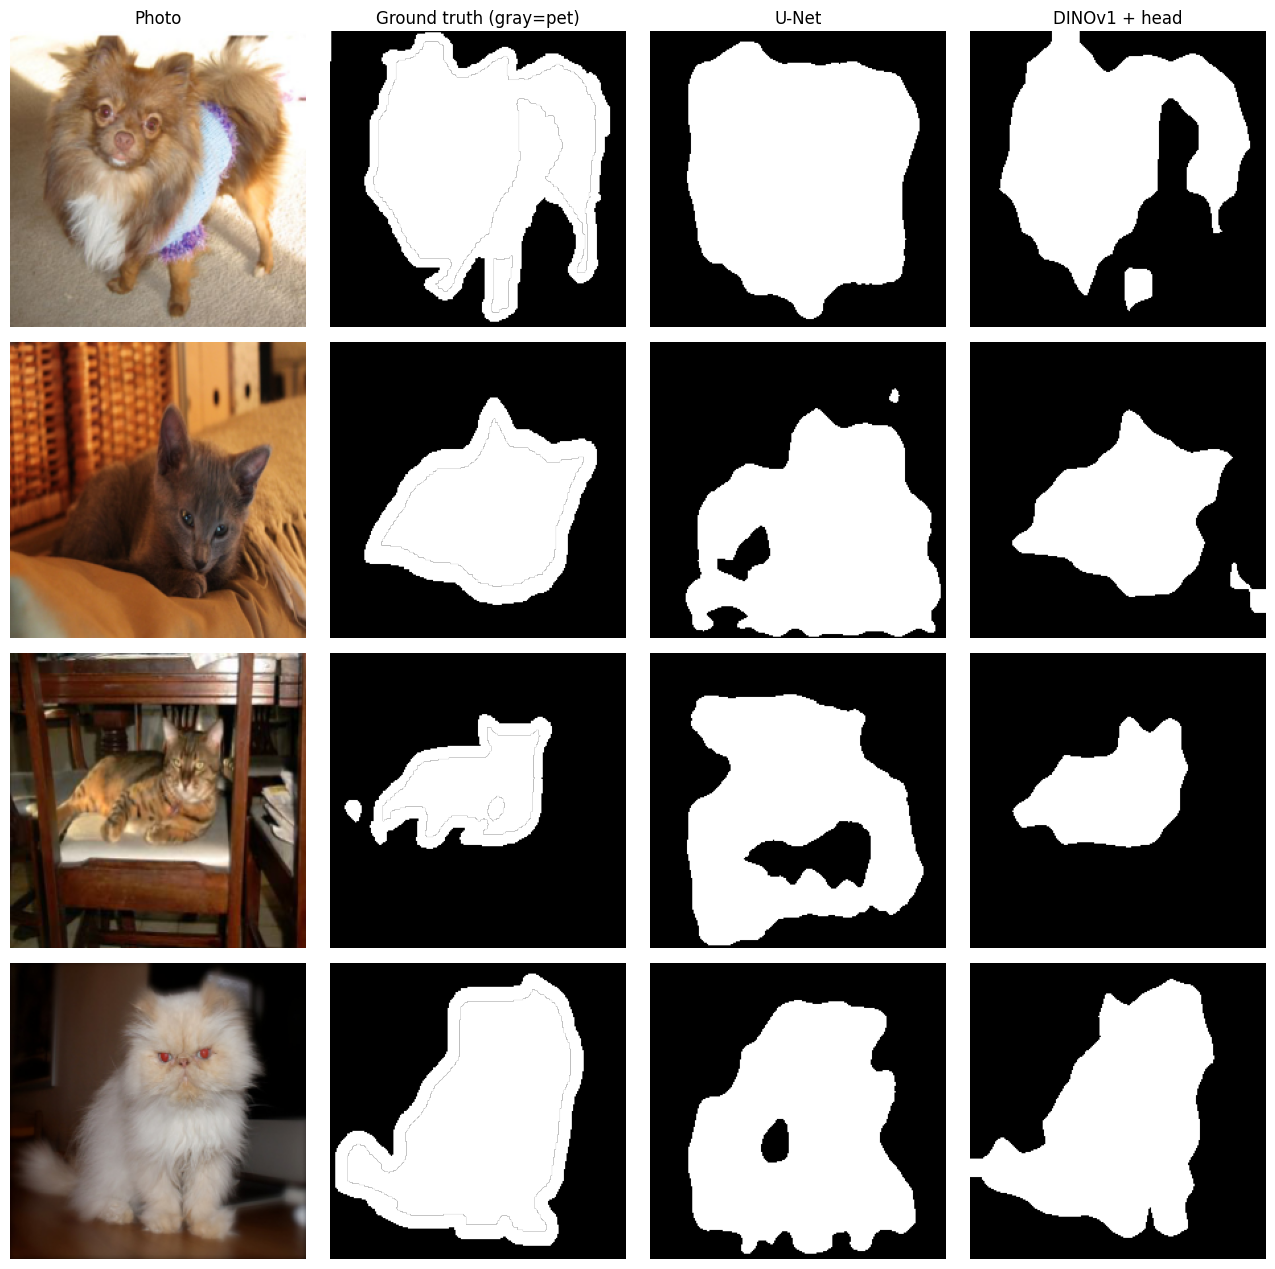

In [ ]:
# Show the *same* test images with GT, U-Net prediction, and DINO prediction.
indices=[0,1,2,3]
fig,axs=plt.subplots(len(indices),4,figsize=(13,3.2*len(indices)))
unet.eval();dino_head.eval()
with torch.no_grad():
    for row,i in enumerate(indices):
        x,y,valid=test_ds[i]
        unet_p=(unet(x[None].to(DEVICE)).sigmoid()[0,0].cpu().numpy()>=.5)
        f=test_cache.tensors[0][i:i+1].to(DEVICE)
        dino_p=(dino_head(f).sigmoid()[0,0].cpu().numpy()>=.5)
        gt=np.where(valid[0].numpy()==0,np.nan,y[0].numpy())
        for col in range(4):axs[row,col].axis('off')
        axs[row,0].imshow(denormalize(x))
        axs[row,1].imshow(gt,cmap='gray',vmin=0,vmax=1)
        axs[row,2].imshow(unet_p,cmap='gray',vmin=0,vmax=1)
        axs[row,3].imshow(dino_p,cmap='gray',vmin=0,vmax=1)
for col,title in enumerate(['Photo','Ground truth (gray=pet)','U-Net','DINOv1 + head']):
    axs[0,col].set_title(title)
plt.tight_layout();plt.show()